In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

In [3]:
df = pd.read_csv('train.csv',usecols=['GarageQual','FireplaceQu','SalePrice'])

In [4]:
df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [5]:
df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

Text(0, 0.5, 'number of house')

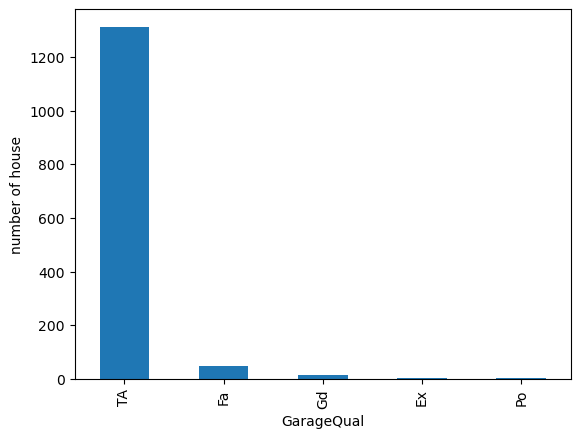

In [6]:


df['GarageQual'].value_counts().sort_values(ascending=False).plot.bar()
plt.xlabel('GarageQual')
plt.ylabel('number of house')

In [7]:
df['GarageQual'].mode

<bound method Series.mode of 0       TA
1       TA
2       TA
3       TA
4       TA
        ..
1455    TA
1456    TA
1457    TA
1458    TA
1459    TA
Name: GarageQual, Length: 1460, dtype: object>

Text(0.5, 1.0, 'GarageQual')

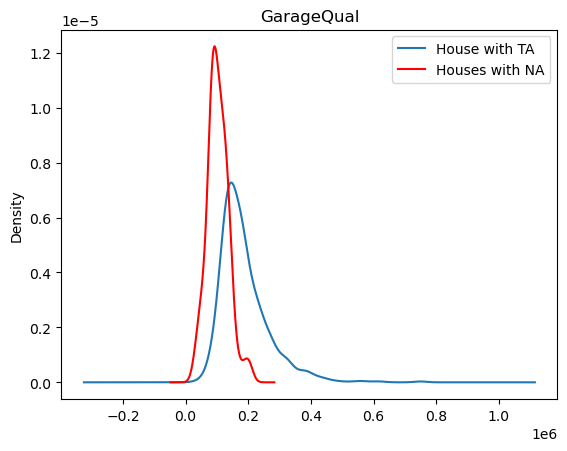

In [8]:
fig =  plt.figure()
ax = fig.add_subplot(111)

df[df['GarageQual']=='TA']['SalePrice'].plot(kind='kde',ax=ax)
df[df['GarageQual'].isnull()]['SalePrice'].plot(kind='kde',ax=ax , color ='red')

lines , labels = ax.get_legend_handles_labels()
labels = ['House with TA','Houses with NA']
ax.legend(lines , labels , loc = 'best')
plt.title('GarageQual')

In [9]:
temp = df[df['GarageQual']=='TA']['SalePrice']

In [10]:
df['GarageQual'].fillna('TA',inplace=True)

<Axes: xlabel='GarageQual'>

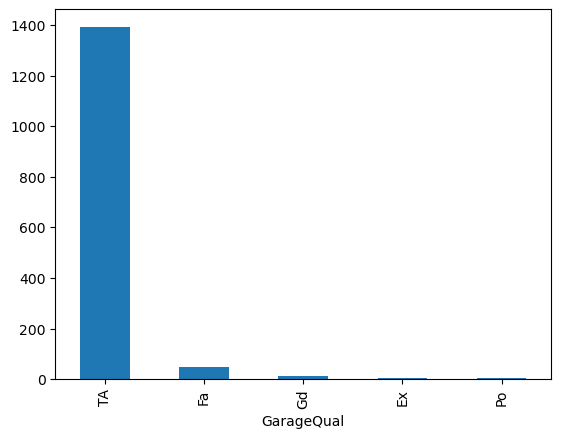

In [11]:
df['GarageQual'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'GarageQual')

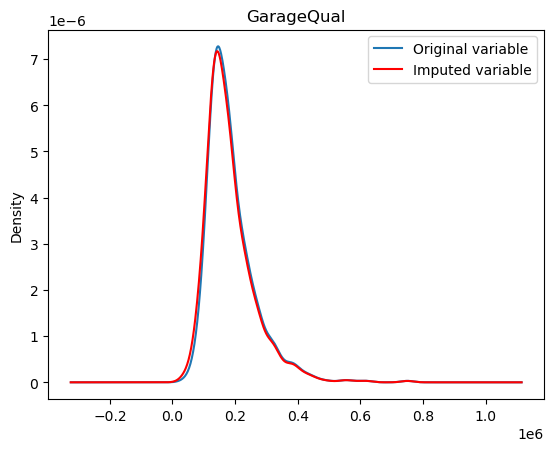

In [13]:
fig = plt.figure()
ax = fig.add_subplot(111)

temp.plot(kind='kde',ax=ax)

# distribution of variable after imputation 

df[df['GarageQual'] == 'TA']['SalePrice'].plot(kind='kde',ax=ax,color='red')
lines , labels = ax.get_legend_handles_labels()
labels = ['Original variable','Imputed variable']
ax.legend(lines , labels , loc = 'best')
plt.title('GarageQual')

<Axes: xlabel='FireplaceQu'>

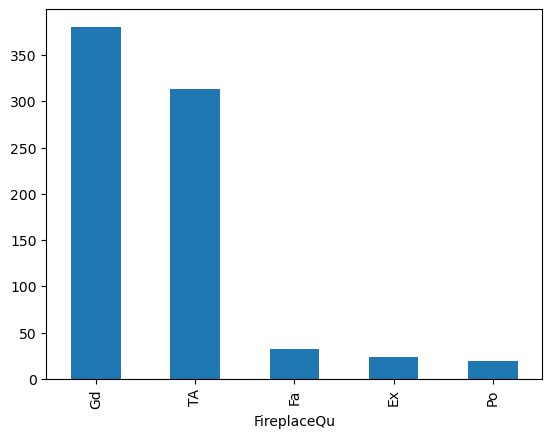

In [14]:
df['FireplaceQu'].value_counts().plot(kind='bar')

In [16]:
df['FireplaceQu'].mode()

0    Gd
Name: FireplaceQu, dtype: object

Text(0.5, 1.0, 'FireplaceQu')

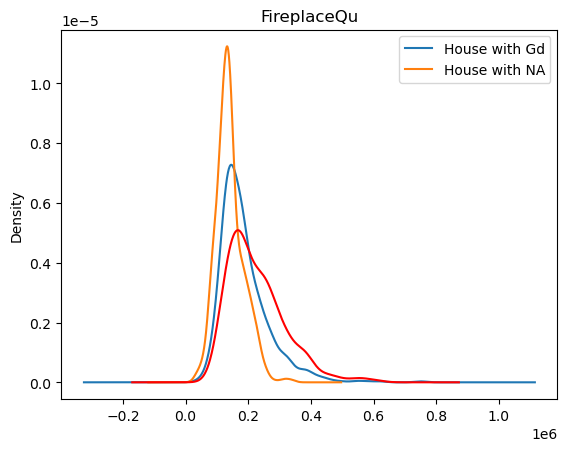

In [19]:
fig = plt.figure()
ax = fig.add_subplot(111)

temp.plot(kind='kde',ax=ax)

df[df['FireplaceQu'].isnull()]['SalePrice'].plot(kind='kde',ax=ax)
df[df['FireplaceQu'] == 'Gd']['SalePrice'].plot(kind='kde',ax=ax,color='red')
lines , labels = ax.get_legend_handles_labels()
labels = ['House with Gd','House with NA']
ax.legend(lines , labels , loc = 'best')
plt.title('FireplaceQu')

In [20]:
temp = df[df['FireplaceQu']=='Gd']['SalePrice']

In [22]:
df['FireplaceQu'].fillna('Gd',inplace=True)

<Axes: xlabel='FireplaceQu'>

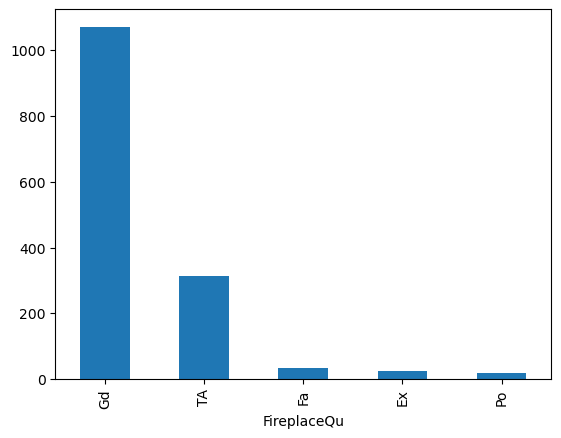

In [23]:
df['FireplaceQu'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'FireplaceQu')

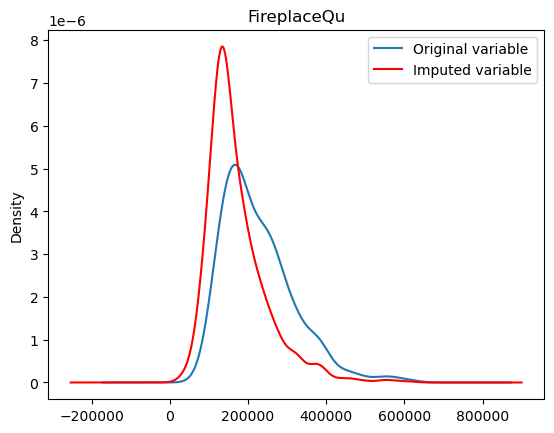

In [24]:
fig = plt.figure()
ax = fig.add_subplot(111)

temp.plot(kind='kde',ax=ax)

# distribution of variable after imputation 

df[df['FireplaceQu'] == 'Gd']['SalePrice'].plot(kind='kde',ax=ax,color='red')
lines , labels = ax.get_legend_handles_labels()
labels = ['Original variable','Imputed variable']
ax.legend(lines , labels , loc = 'best')
plt.title('FireplaceQu')

In [29]:
from sklearn.model_selection import train_test_split 

X_train , X_test ,  y_train , y_test = train_test_split(df.drop(columns=['SalePrice']), df['SalePrice'], test_size=0.2)

In [32]:
from sklearn.impute import SimpleImputer


In [33]:
imputer = SimpleImputer(strategy='most_frequent')

In [34]:
X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_train)

C:\Users\yogen\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


In [35]:
imputer.statistics_

array(['Gd', 'TA'], dtype=object)